# Research Question 7 — Quality-of-Life Features and Stress Level

**Research question:** Is there a correlation between certain *quality-of-life* features and stress level?

Our hypothesis is the three explanatory variables and states the expectation up front: more
physical activity, more study time and more sleep should go together with *lower* stress. This notebook
tests whether that expectation actually holds in the data.

**Quality-of-life (QoL) features** — the three explanatory variables, and nothing else:

| Column | Meaning |
|---|---|
| `Physical_Activity_Hours` | hours of physical activity per day |
| `Study_Hours` | study hours per day |
| `Sleep_Hours_Per_Night` | sleep hours per night |

**Outcomes** — two of them, so the same question is answered on both scales:

| Column | Scale | Direction |
|---|---|---|
| `Stress_Level` | ordinal, 4 levels: `Low` < `Medium` < `High` < `Very High` | higher = worse |
| `Mental_Health_Score` | continuous, 3.6–9.4 | higher = better |

Stress level is the primary outcome named in our research question; the mental-health score is carried
alongside it as a continuous secondary outcome, which also lets us use parametric tests as a cross-check
on the rank-based ones.

## Hypotheses

Tested separately for each of the three quality-of-life features.

**H0 (null):** the feature has no monotonic association with stress level — the distribution of
`Physical_Activity_Hours` / `Study_Hours` / `Sleep_Hours_Per_Night` is the same across the four stress
levels, and the rank correlation with stress is zero.

**H1 (alternative):** the feature is monotonically associated with stress level, and specifically
*negatively* — students with more activity, study time or sleep sit at lower stress levels. This is the
direction the research proposal predicts.

Significance level: **α = 0.05** throughout. Because n ≈ 5000, effect sizes are reported next to every
p-value: at this sample size a trivially small association is still "significant", so the p-value alone
would be misleading.

## 0. Setup & Data Loading

In [17]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

np.seterr(all='ignore')  # this environment's BLAS emits spurious matmul warnings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
pd.set_option('display.width', 180)  # keep the wide result tables on one line
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

# Cleaned dataset exported by data_exploration/01_data_overview_and_distributions.ipynb
# (exact duplicate rows removed, negative values clipped to 0)
DATA_PATH = '../dataset/student_social_media_cleaned.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f'{DATA_PATH} not found — run data_exploration/01_data_overview_and_distributions.ipynb first'
    )
df = pd.read_csv(DATA_PATH)

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
df['Stress_Level'] = pd.Categorical(df['Stress_Level'], categories=STRESS_ORDER, ordered=True)

# Ordinal encoding of stress (0..3) — same convention as data_exploration/02 and Questions/02
stress_map = {lvl: i for i, lvl in enumerate(STRESS_ORDER)}
df['Stress_Level_Enc'] = df['Stress_Level'].map(stress_map).astype(int)

# Binary target for the classification model in section 7
df['High_Stress'] = df['Stress_Level'].isin(['High', 'Very High']).astype(int)

QOL_COLS   = ['Physical_Activity_Hours', 'Study_Hours', 'Sleep_Hours_Per_Night']
STRESS_COL = 'Stress_Level'
STRESS_ENC = 'Stress_Level_Enc'
MHS_COL    = 'Mental_Health_Score'
USAGE_COL  = 'Avg_Daily_Usage_Hours'
STRESS_PALETTE = sns.color_palette('YlOrRd', 4)

# Readable axis labels for the three QoL features
QOL_LABELS = {
    'Physical_Activity_Hours': 'Physical activity (h/day)',
    'Study_Hours':             'Study time (h/day)',
    'Sleep_Hours_Per_Night':   'Sleep (h/night)',
}

print('Shape:', df.shape)
print('\nStress level counts:')
print(df[STRESS_COL].value_counts().reindex(STRESS_ORDER).to_string())
print('\nQuality-of-life features:')
print(df[QOL_COLS].describe().round(3).to_string())
print(f'\nHigh-stress base rate: {df["High_Stress"].mean():.1%}')

Shape: (4998, 15)

Stress level counts:
Stress_Level
Low           643
Medium       1295
High         1439
Very High    1621

Quality-of-life features:
       Physical_Activity_Hours  Study_Hours  Sleep_Hours_Per_Night
count                 4998.000     4998.000               4998.000
mean                     1.751        3.008                  6.635
std                      0.667        1.637                  1.222
min                     -0.000        0.300                  3.600
25%                      1.300        1.500                  5.600
50%                      1.700        2.800                  6.600
75%                      2.200        4.200                  7.500
max                      4.100        8.300                  9.900

High-stress base rate: 61.2%


## 1. Reproducibility Checks

A short guard so that a silent change upstream (a renamed column, a relabelled category) fails loudly here
rather than producing a plausible-looking but wrong result further down.

In [18]:
required_cols = QOL_COLS + [STRESS_COL, MHS_COL, USAGE_COL]

assert all(col in df.columns for col in required_cols), 'missing required column(s)'
assert set(df[STRESS_COL].dropna().unique()) == set(STRESS_ORDER), 'unexpected stress labels'
assert df[required_cols].notna().all().all(), 'unexpected missing values'

print(f'Observations used: {len(df):,}')
print(f'Missing values in the columns we use: {int(df[required_cols].isna().sum().sum())}')
print('\nOutcome scales:')
print(f'  {STRESS_COL:<20} ordinal, {len(STRESS_ORDER)} levels: ' + ' < '.join(STRESS_ORDER))
print(f'  {MHS_COL:<20} continuous, {df[MHS_COL].min():.1f} to {df[MHS_COL].max():.1f}')

Observations used: 4,998
Missing values in the columns we use: 0

Outcome scales:
  Stress_Level         ordinal, 4 levels: Low < Medium < High < Very High
  Mental_Health_Score  continuous, 3.6 to 9.4


## 2. Descriptive Comparison

Before any test, look at the raw pattern: what do the three quality-of-life features look like at each
stress level? If the proposal's expectation is right, every column should fall as we move from `Low` to
`Very High`.

In [ ]:
desc = (df.groupby(STRESS_COL, observed=True)[QOL_COLS]
          .agg(['mean', 'median', 'std'])
          .reindex(STRESS_ORDER)
          .round(3))
print('Quality-of-life features by stress level:')
print(desc.to_string())

print('\nGroup sizes:')
print(df[STRESS_COL].value_counts().reindex(STRESS_ORDER).to_string())

# The two outcomes plus daily social-media usage, for orientation only
print('\nFor orientation — outcome and usage means by stress level:')
print(df.groupby(STRESS_COL, observed=True)[[MHS_COL, USAGE_COL]]
        .mean().reindex(STRESS_ORDER).round(3).to_string())

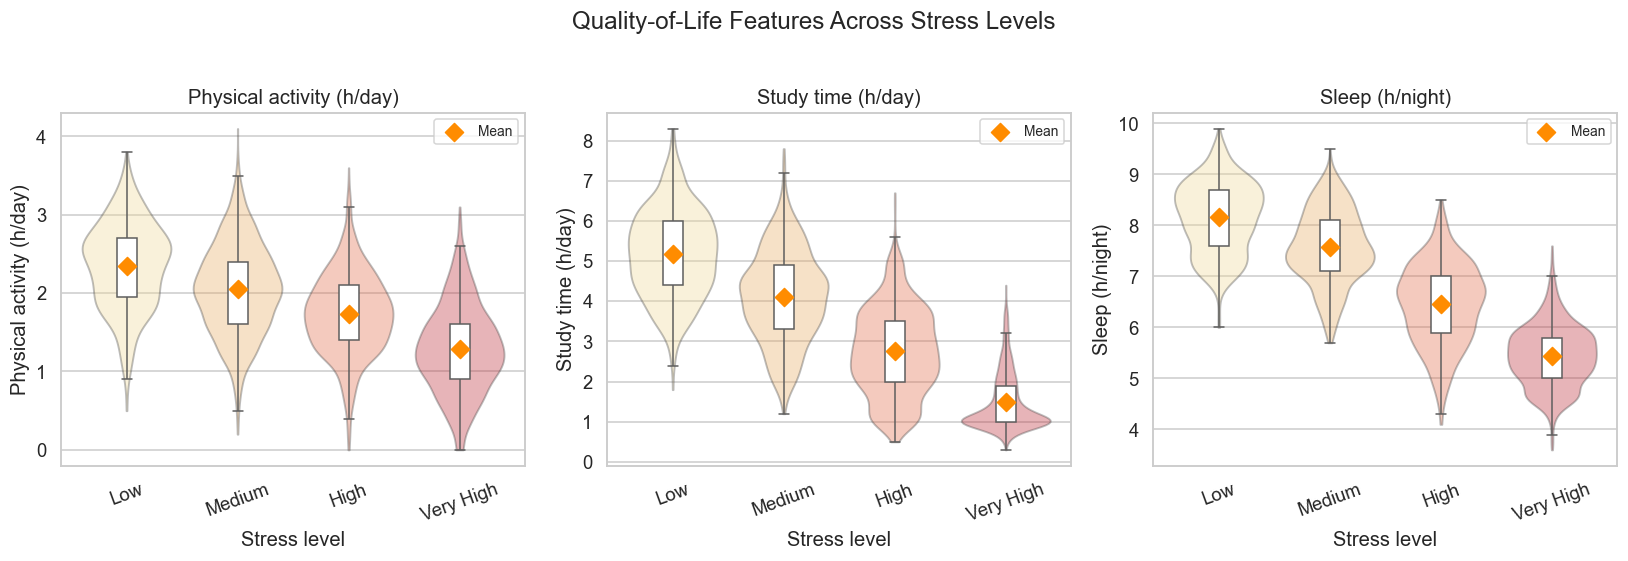

In [20]:
# Violin + narrow box per stress level, one panel per QoL feature
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, QOL_COLS):
    sns.violinplot(data=df, x=STRESS_COL, y=col, order=STRESS_ORDER,
                   palette=STRESS_PALETTE, inner=None, cut=0, alpha=0.35, ax=ax)
    sns.boxplot(data=df, x=STRESS_COL, y=col, order=STRESS_ORDER, width=0.18,
                showcaps=True, boxprops={'facecolor': 'white', 'zorder': 3},
                whiskerprops={'zorder': 3}, showfliers=False, ax=ax)
    means = df.groupby(STRESS_COL, observed=True)[col].mean().reindex(STRESS_ORDER)
    ax.scatter(range(len(STRESS_ORDER)), means.values, color='darkorange', s=70,
               zorder=5, marker='D', label='Mean')
    ax.set_title(QOL_LABELS[col])
    ax.set_xlabel('Stress level')
    ax.set_ylabel(QOL_LABELS[col])
    ax.tick_params(axis='x', rotation=20)
    ax.legend(loc='upper right', fontsize=9)

fig.suptitle('Quality-of-Life Features Across Stress Levels', y=1.02)
plt.tight_layout()
plt.show()

### What the results tell us

All three features decline monotonically from `Low` to `Very High` stress, in the direction the proposal
predicted, and the decline is not subtle: mean study time drops from roughly 5.2 to 1.5 hours a day and
mean sleep from about 8.2 to 5.4 hours a night. Physical activity falls too, but over a much narrower
absolute range (roughly 2.4 to 1.3 hours), and the violins overlap far more — a first hint that its
association is the weakest of the three.


## 3. Rank Correlation with Ordinal Stress

Stress level is an **ordered category**, not a number, so a Pearson correlation is not the right tool: it
would assume the gaps `Low`→`Medium` and `High`→`Very High` are equal and numerically meaningful. Rank
correlations only use the *ordering*, which is exactly the information the variable carries.

Two of them are reported, because they answer the same question with different arithmetic:
- **Spearman's ρ** — Pearson correlation computed on ranks.
- **Kendall's τ-b** — the proportion of concordant minus discordant pairs, with a correction for the heavy
  tie structure that a 4-level variable inevitably produces. τ is systematically smaller than ρ; that is a
  property of the statistic, not a weaker result.

**Understanding the p-value.** The null hypothesis is that the true rank correlation between the
quality-of-life feature and stress level is **zero** — that any correlation we see in this sample is chance.
The p-value is the probability of a correlation at least this far from zero if the null were true.

- p < 0.05 → reject the null; a monotonic association is present.
- p ≥ 0.05 → we cannot reject the null; no evidence of a monotonic association.

The p-value says nothing about *size*, so the coefficient and its magnitude label are what carry the
practical meaning.

In [21]:
def interpret_r(r):
    """Magnitude label for a correlation coefficient (sign ignored)."""
    a = abs(r)
    if a < 0.10: return 'negligible'
    if a < 0.30: return 'weak'
    if a < 0.50: return 'moderate'
    if a < 0.70: return 'strong'
    return 'very strong'

rows = []
for col in QOL_COLS:
    rho, p_rho = stats.spearmanr(df[col], df[STRESS_ENC])
    tau, p_tau = stats.kendalltau(df[col], df[STRESS_ENC])
    rows.append({'Feature': col, 'Test': "Spearman ρ", 'Statistic': round(rho, 4),
                 'p-value': p_rho, 'Significant (α=0.05)': p_rho < 0.05,
                 'Effect size': f'ρ={rho:+.3f}', 'Magnitude': interpret_r(rho)})
    rows.append({'Feature': col, 'Test': "Kendall τ-b", 'Statistic': round(tau, 4),
                 'p-value': p_tau, 'Significant (α=0.05)': p_tau < 0.05,
                 'Effect size': f'τ={tau:+.3f}', 'Magnitude': interpret_r(tau)})

corr_results = pd.DataFrame(rows)
print('Rank correlation with stress level (encoded 0=Low .. 3=Very High):')
print(corr_results.to_string(index=False))
print('\nA negative coefficient means: more of the feature goes with a LOWER stress level.')

Rank correlation with stress level (encoded 0=Low .. 3=Very High):
                Feature        Test  Statistic  p-value  Significant (α=0.05) Effect size   Magnitude
Physical_Activity_Hours  Spearman ρ    -0.5598      0.0                  True    ρ=-0.560      strong
Physical_Activity_Hours Kendall τ-b    -0.4459      0.0                  True    τ=-0.446    moderate
            Study_Hours  Spearman ρ    -0.8000      0.0                  True    ρ=-0.800 very strong
            Study_Hours Kendall τ-b    -0.6594      0.0                  True    τ=-0.659      strong
  Sleep_Hours_Per_Night  Spearman ρ    -0.8215      0.0                  True    ρ=-0.822 very strong
  Sleep_Hours_Per_Night Kendall τ-b    -0.6785      0.0                  True    τ=-0.679      strong

A negative coefficient means: more of the feature goes with a LOWER stress level.


### What the results tell us

Every coefficient is negative and every p-value is far below 0.05, so H0 is rejected for all three features
and the sign matches the proposal's expectation in each case. What the coefficients add is a clear ranking:

- **Sleep hours** (ρ ≈ −0.82) and **study hours** (ρ ≈ −0.80) are *very strong* associations.
- **Physical activity** (ρ ≈ −0.56) is real but distinctly weaker — *strong* by the label, roughly half the
  shared variance of the other two.

Kendall's τ tells the same story at its own smaller scale (−0.68, −0.66, −0.45), which is the point of
reporting it: the ordering of the three features is not an artifact of one particular statistic.

## 4. Group Comparison — Kruskal–Wallis

The correlation in section 3 asks "does the feature trend with stress?". A different and complementary
question is "do the four stress groups differ at all in this feature?" — which is a group comparison.

**Kruskal–Wallis** rather than one-way ANOVA, for two reasons: the grouping variable is ordinal, and ANOVA
assumes normally distributed, equal-variance groups, which these hour columns do not satisfy. Kruskal–Wallis
is the rank-based equivalent and makes neither assumption.

The effect size is **epsilon-squared**, ε² = (H − k + 1) / (n − k), the share of rank variance explained by
the grouping (0 = none, 1 = perfect separation).

**Understanding the p-value.** For Kruskal–Wallis the null hypothesis is that the feature's distribution is
**identical across all four stress levels**.

- p < 0.05 → reject the null; the groups differ.
- p ≥ 0.05 → no evidence that they differ.

In [22]:
def epsilon_squared(H, n, k):
    """Kruskal-Wallis effect size: share of rank variance explained by the grouping."""
    return (H - k + 1) / (n - k)

def interpret_effect(a):
    """Generic |effect| label for epsilon-squared / rank-biserial style magnitudes."""
    a = abs(a)
    if a < 0.01: return 'negligible'
    if a < 0.06: return 'small'
    if a < 0.14: return 'medium'
    return 'large'

k = len(STRESS_ORDER)
n = len(df)

rows = []
for col in QOL_COLS:
    groups = [df.loc[df[STRESS_COL] == lvl, col].values for lvl in STRESS_ORDER]
    H, p = stats.kruskal(*groups)
    eps2 = epsilon_squared(H, n, k)
    rows.append({'Feature': col, 'Test': 'Kruskal-Wallis H', 'Statistic': round(H, 2),
                 'p-value': p, 'Significant (α=0.05)': p < 0.05,
                 'Effect size': f'ε²={eps2:.3f}', 'Magnitude': interpret_effect(eps2)})

kw_results = pd.DataFrame(rows)
print(f'Kruskal-Wallis across the {k} stress levels (n={n:,}):')
print(kw_results.to_string(index=False))

Kruskal-Wallis across the 4 stress levels (n=4,998):
                Feature             Test  Statistic  p-value  Significant (α=0.05) Effect size Magnitude
Physical_Activity_Hours Kruskal-Wallis H    1569.37      0.0                  True    ε²=0.314     large
            Study_Hours Kruskal-Wallis H    3199.36      0.0                  True    ε²=0.640     large
  Sleep_Hours_Per_Night Kruskal-Wallis H    3388.44      0.0                  True    ε²=0.678     large


### What the results tell us

Kruskal–Wallis rejects H0 for all three features, and ε² separates them the same way section 3 did: sleep
(ε² ≈ 0.68) and study hours (ε² ≈ 0.64) explain roughly two-thirds of the rank variance in stress, while
physical activity (ε² ≈ 0.31) explains under a third. All three are "large" by the conventional threshold,
so the label alone understates the gap — the numbers matter more than the word.

## 5. Chi-Square Test on Binned Features

The tests so far treated the quality-of-life features as continuous. A chi-square test of independence
approaches the same question from the categorical side: split each feature into quartiles and ask whether
the *distribution of stress levels* differs across those quartiles.

This is a weaker test than the rank correlation — binning throws away information — but it earns its place
for two reasons. It makes no assumption whatsoever about linearity or monotonicity, so it would still detect
a U-shaped relationship that a rank correlation could miss; and its residuals (section below) show exactly
*where* in the table the association lives.

Effect size is **Cramér's V**, with thresholds adjusted for the table's degrees of freedom — for a 4×4 table
min(r−1, c−1) = 3, where the conventional 0.10/0.30/0.50 cut-offs are too strict.

**Understanding the p-value.** The null hypothesis is that the binned quality-of-life feature and stress
level are **independent** — knowing which quartile a student falls in tells you nothing about their stress
level. The p-value is the probability of a table at least this far from the independence expectation if the
null were true.

- p < 0.05 → reject independence; the two variables are associated.
- p ≥ 0.05 → no evidence of association.

Chi-square requires expected cell counts of at least 5, so that assumption is checked explicitly before the
result is read.

In [23]:
def cramers_v_from_chi2(chi2, n_obs, table_shape):
    """Cramér's V effect size from a chi-square statistic."""
    r, c = table_shape
    return np.sqrt((chi2 / n_obs) / min(r - 1, c - 1))

def interpret_cramers_v(v, deg_freedom_min):
    # Thresholds widen as the table grows; df_min = min(r-1, c-1)
    if deg_freedom_min == 1:
        thresholds = [0.10, 0.30, 0.50]
    elif deg_freedom_min == 2:
        thresholds = [0.07, 0.21, 0.35]
    else:
        thresholds = [0.06, 0.17, 0.29]
    if v < thresholds[0]:
        return 'negligible'
    elif v < thresholds[1]:
        return 'small'
    elif v < thresholds[2]:
        return 'medium'
    return 'large'

# Quartile bins per feature, kept for the residual heatmap below
binned = {col: pd.qcut(df[col], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'],
                       duplicates='drop')
          for col in QOL_COLS}

chi_rows, tables, expected_tables = [], {}, {}
for col in QOL_COLS:
    ct = pd.crosstab(binned[col], df[STRESS_COL])
    ct = ct.reindex(columns=STRESS_ORDER)
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    v = cramers_v_from_chi2(chi2, ct.values.sum(), ct.shape)
    tables[col] = ct
    expected_tables[col] = pd.DataFrame(expected, index=ct.index, columns=ct.columns)
    chi_rows.append({'Feature': col, 'Test': f'Chi-square (dof={dof})',
                     'Statistic': round(chi2, 2), 'p-value': p,
                     'Significant (α=0.05)': p < 0.05,
                     'Effect size': f'V={v:.3f}',
                     'Magnitude': interpret_cramers_v(v, min(ct.shape[0] - 1, ct.shape[1] - 1)),
                     'Min expected count': round(expected.min(), 1),
                     'Assumption (all ≥5)': bool(expected.min() >= 5)})

chi_results = pd.DataFrame(chi_rows)
print('Chi-square test of independence — QoL quartile × stress level (4×4 tables):')
print(chi_results.to_string(index=False))

print(f'\nRow percentages for {QOL_COLS[2]} (illustrative — the strongest association):')
pct = (tables[QOL_COLS[2]].div(tables[QOL_COLS[2]].sum(axis=1), axis=0) * 100).round(1)
print(pct.to_string())

Chi-square test of independence — QoL quartile × stress level (4×4 tables):
                Feature               Test  Statistic  p-value  Significant (α=0.05) Effect size Magnitude  Min expected count  Assumption (all ≥5)
Physical_Activity_Hours Chi-square (dof=9)    1639.80      0.0                  True     V=0.331     large               142.3                 True
            Study_Hours Chi-square (dof=9)    3889.05      0.0                  True     V=0.509     large               156.1                 True
  Sleep_Hours_Per_Night Chi-square (dof=9)    3982.35      0.0                  True     V=0.515     large               158.1                 True

Row percentages for Sleep_Hours_Per_Night (illustrative — the strongest association):
Stress_Level            Low  Medium  High  Very High
Sleep_Hours_Per_Night                               
Q1 (lowest)             0.0     0.0  19.2       80.8
Q2                      0.4    11.3  44.4       43.9
Q3                     11.9    41

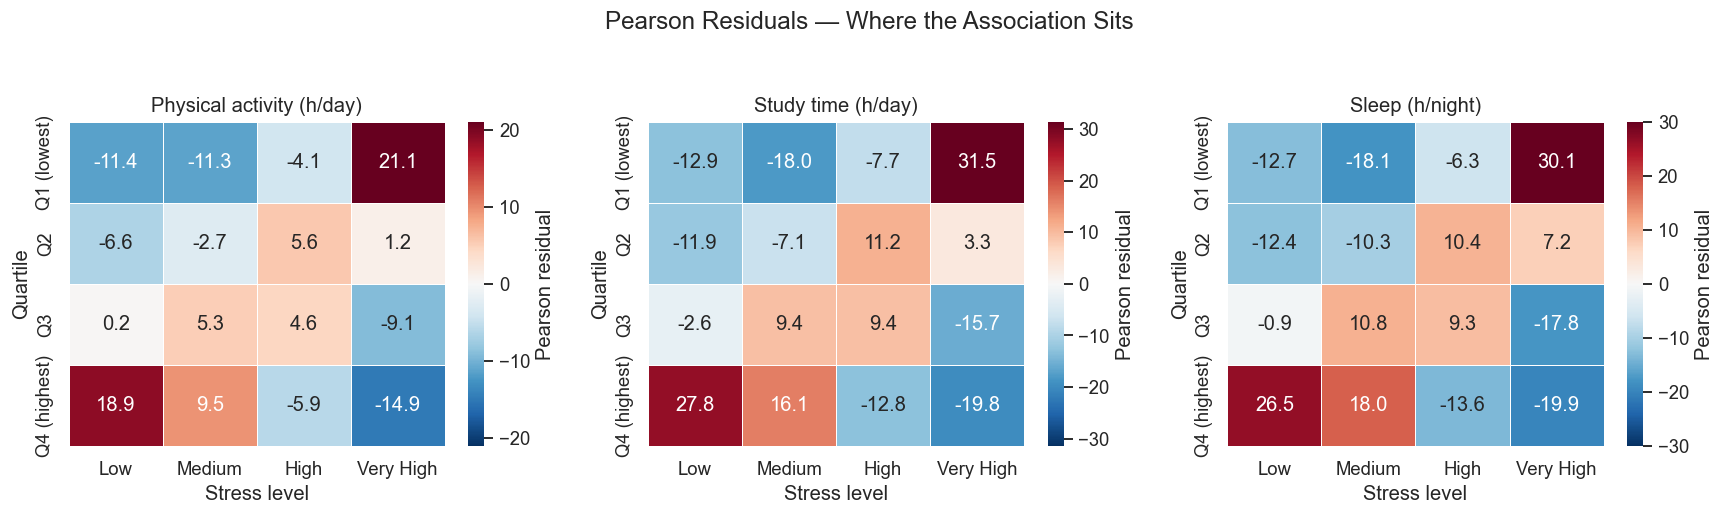

In [24]:
# Pearson residuals: (observed - expected) / sqrt(expected). Red = more students than
# independence predicts, blue = fewer.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, QOL_COLS):
    resid = (tables[col] - expected_tables[col]) / np.sqrt(expected_tables[col])
    limit = resid.abs().to_numpy().max()
    sns.heatmap(resid, annot=True, fmt='.1f', cmap='RdBu_r', center=0,
                vmin=-limit, vmax=limit, linewidths=0.4,
                cbar_kws={'label': 'Pearson residual'}, ax=ax)
    ax.set_title(QOL_LABELS[col])
    ax.set_xlabel('Stress level')
    ax.set_ylabel('Quartile')

fig.suptitle('Pearson Residuals — Where the Association Sits', y=1.04)
plt.tight_layout()
plt.show()

### What the results tell us

Independence is rejected for all three features, with every expected count comfortably above the required 5
(the smallest is in the hundreds), so the test is on solid ground. Cramér's V again ranks sleep (≈ 0.52) and
study hours (≈ 0.51) above physical activity (≈ 0.33) — all "large", but with the same two-to-one gap.

The residual heatmaps show a clean diagonal structure: the lowest quartile of each feature is
over-represented at `Very High` stress and under-represented at `Low`, and the pattern reverses smoothly
across the table. That diagonal is what a monotonic association looks like in a contingency table, and it
confirms the rank correlations were not hiding a non-linear shape. The physical-activity panel shows the
same diagonal with visibly paler extremes — a weaker version of the same relationship, not a different one.

## 6. Secondary Outcome — Mental Health Score

`Mental_Health_Score` is continuous, so the parametric route is available here: **Pearson's r** measures the
strength of the linear relationship directly, and **Spearman's ρ** is reported next to it as a robustness
check — if the two agree closely, the relationship is well described as linear and not driven by outliers.

Because Pearson's r is the more assumption-heavy statistic, normality is checked first with D'Agostino–Pearson.

One thing to keep in mind when reading the signs: a **higher** mental-health score is *better*, whereas a
higher stress level is *worse*. So the correlations in this section should be **positive** wherever section 3
was negative. A sign flip here means the two outcomes agree.

**Understanding the p-value.** For the normality test the null hypothesis is that the variable is drawn from
a normal distribution (p < 0.05 → not normal). For the correlations the null is that the true correlation
with `Mental_Health_Score` is **zero**.

- p < 0.05 → reject the null; a real association is present.
- p ≥ 0.05 → no evidence of association.

At n ≈ 5000 the normality test is extremely sensitive and will flag deviations far too small to trouble a
correlation, so it is read as a description of shape rather than a gate on the analysis — Spearman's ρ is
what actually guards against that concern.

In [25]:
# Normality of each variable involved (descriptive — see the note above)
norm_rows = []
for col in QOL_COLS + [MHS_COL]:
    stat, p = stats.normaltest(df[col])
    norm_rows.append({'Variable': col, 'normaltest stat': round(stat, 2), 'p-value': p,
                      'Distribution': 'Normal' if p > 0.05 else 'Not normal',
                      'Skew': round(stats.skew(df[col]), 3),
                      'Excess kurtosis': round(stats.kurtosis(df[col]), 3)})
print("D'Agostino-Pearson normality check:")
print(pd.DataFrame(norm_rows).to_string(index=False))

# Pearson + Spearman against the continuous outcome
mhs_rows = []
for col in QOL_COLS:
    r, p_r = stats.pearsonr(df[col], df[MHS_COL])
    rho, p_rho = stats.spearmanr(df[col], df[MHS_COL])
    mhs_rows.append({'Feature': col, 'Test': 'Pearson r', 'Statistic': round(r, 4),
                     'p-value': p_r, 'Significant (α=0.05)': p_r < 0.05,
                     'Effect size': f'r={r:+.3f}', 'Magnitude': interpret_r(r)})
    mhs_rows.append({'Feature': col, 'Test': 'Spearman ρ', 'Statistic': round(rho, 4),
                     'p-value': p_rho, 'Significant (α=0.05)': p_rho < 0.05,
                     'Effect size': f'ρ={rho:+.3f}', 'Magnitude': interpret_r(rho)})

mhs_results = pd.DataFrame(mhs_rows)
print(f'\nCorrelation with {MHS_COL} (higher score = better mental health):')
print(mhs_results.to_string(index=False))
print('\nA positive coefficient means: more of the feature goes with a BETTER mental-health score.')

D'Agostino-Pearson normality check:
               Variable  normaltest stat       p-value Distribution  Skew  Excess kurtosis
Physical_Activity_Hours            20.89  2.906522e-05   Not normal 0.053           -0.261
            Study_Hours           442.43  8.470240e-97   Not normal 0.436           -0.726
  Sleep_Hours_Per_Night           630.40 1.290289e-137   Not normal 0.124           -0.880
    Mental_Health_Score           462.32 4.068182e-101   Not normal 0.207           -0.803

Correlation with Mental_Health_Score (higher score = better mental health):
                Feature       Test  Statistic  p-value  Significant (α=0.05) Effect size   Magnitude
Physical_Activity_Hours  Pearson r     0.5218      0.0                  True    r=+0.522      strong
Physical_Activity_Hours Spearman ρ     0.5259      0.0                  True    ρ=+0.526      strong
            Study_Hours  Pearson r     0.7525      0.0                  True    r=+0.752 very strong
            Study_Hours Spea

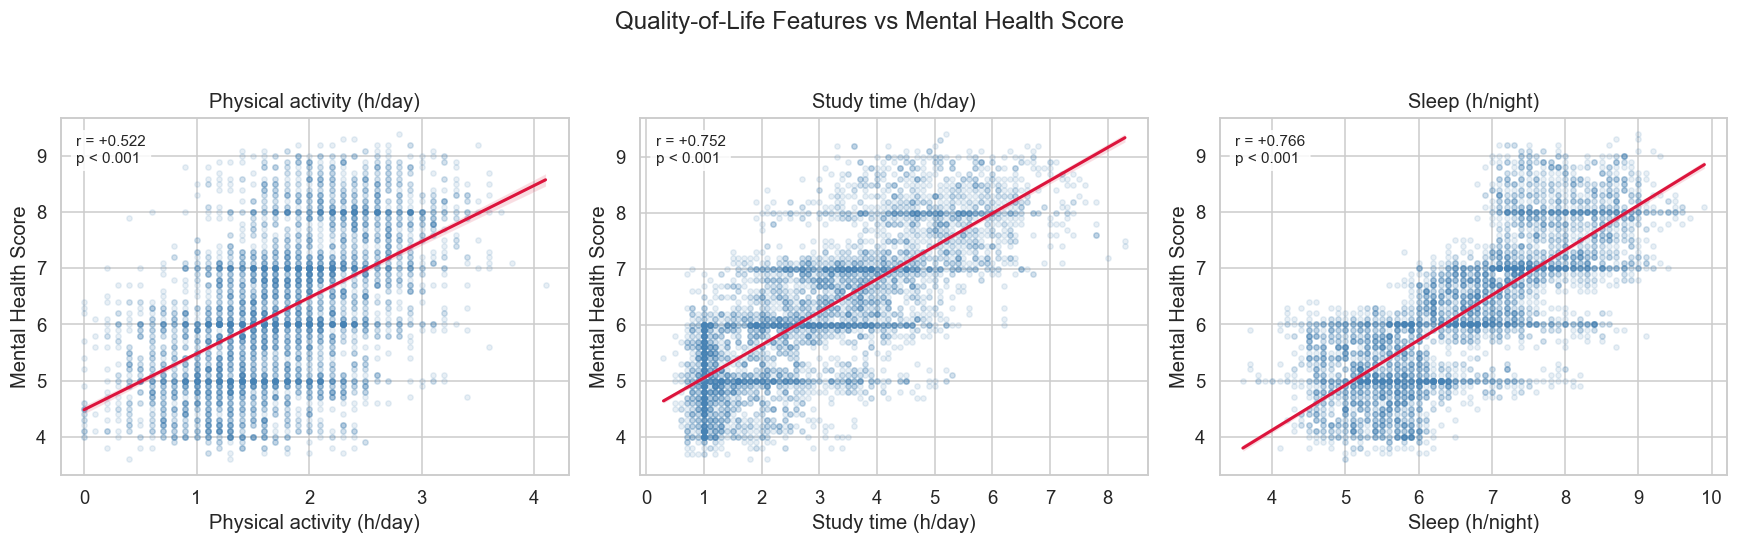

In [26]:
# Scatter + regression line per QoL feature against the continuous outcome
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, col in zip(axes, QOL_COLS):
    sns.regplot(data=df, x=col, y=MHS_COL, ax=ax,
                scatter_kws={'alpha': 0.12, 's': 12, 'color': 'steelblue'},
                line_kws={'color': 'crimson', 'linewidth': 2})
    r, p = stats.pearsonr(df[col], df[MHS_COL])
    p_txt = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    ax.annotate(f'r = {r:+.3f}\n{p_txt}', xy=(0.03, 0.95), xycoords='axes fraction',
                va='top', fontsize=10,
                bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.85})
    ax.set_title(QOL_LABELS[col])
    ax.set_xlabel(QOL_LABELS[col])
    ax.set_ylabel('Mental Health Score')

fig.suptitle('Quality-of-Life Features vs Mental Health Score', y=1.03)
plt.tight_layout()
plt.show()

### What the results tell us

The secondary outcome tells the same story as the primary one, with the sign flipped as expected: sleep
(r ≈ +0.77) and study hours (r ≈ +0.75) are *very strong* positive correlates of mental-health score, and
physical activity (r ≈ +0.52) is again the weakest of the three.

Pearson and Spearman agree to within about 0.03 on every feature, so these relationships are close to
linear and not being driven by a handful of extreme points. The scatter plots confirm it visually — a broad
but clearly tilted band with no curvature and no detached clusters.

Two outcomes measured on different scales, tested with different families of statistics (rank-based vs
parametric), producing the same ranking of the same three features: that consistency is the strongest
evidence in this notebook that the marginal association is real.

## 7. Basic Machine-Learning Models

One basic model per outcome. The point is not to build the best possible predictor — that is Question 8's
job — but to answer two things the correlations cannot:

1. **Jointly**, how much of each outcome do the three quality-of-life features account for?
2. **Relatively**, which feature carries the weight once the other two are in the model? A correlation looks
   at one feature in isolation; a coefficient is a feature's contribution *given the others*.

- `Stress_Level` is a 4-level ordinal, which no plain classifier handles natively, so it is collapsed to a
  binary **`High_Stress`** = {`High`, `Very High`} and modelled with **logistic regression**. Accuracy is
  reported against the majority-class baseline, since 61.2% is what guessing "high" every time already gets.
- `Mental_Health_Score` is continuous and modelled with **linear regression**, scored by R².

Both are evaluated with **5-fold cross-validation** (the convention in this project), and both use
standardized features so the coefficients are directly comparable to one another.

Logistic regression — High_Stress ~ 3 quality-of-life features
  majority-class baseline : 0.6122
  CV accuracy             : 0.8836 ± 0.0116
  CV ROC-AUC              : 0.9589 ± 0.0108
  improvement over baseline: +0.2713

Odds of being in the high-stress group, per one standard deviation increase:
                Feature  Coef (standardized)  Odds ratio per +1 SD
Physical_Activity_Hours              -0.3364                0.7144
            Study_Hours              -1.4869                0.2261
  Sleep_Hours_Per_Night              -2.2281                0.1077
(odds ratio < 1 = lower odds of high stress; 1.0 = no effect)


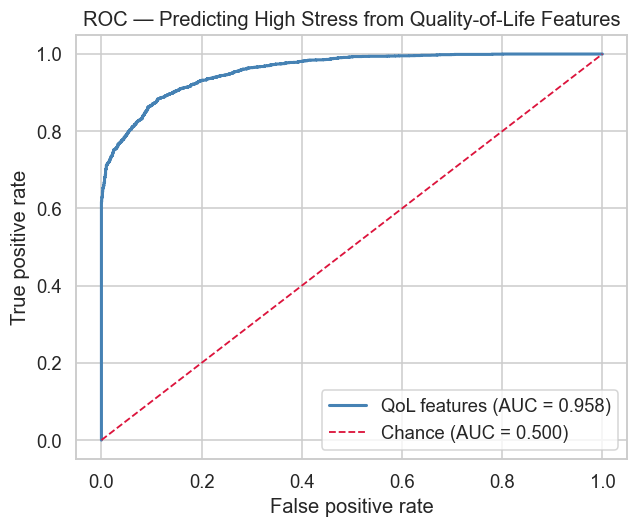

In [27]:
X_qol = df[QOL_COLS].astype(float)
y_cls = df['High_Stress'].values
baseline = max(df['High_Stress'].mean(), 1 - df['High_Stress'].mean())

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
acc = cross_val_score(clf, X_qol, y_cls, cv=5, scoring='accuracy')
auc = cross_val_score(clf, X_qol, y_cls, cv=5, scoring='roc_auc')

print('Logistic regression — High_Stress ~ 3 quality-of-life features')
print(f'  majority-class baseline : {baseline:.4f}')
print(f'  CV accuracy             : {acc.mean():.4f} ± {acc.std():.4f}')
print(f'  CV ROC-AUC              : {auc.mean():.4f} ± {auc.std():.4f}')
print(f'  improvement over baseline: {acc.mean() - baseline:+.4f}')

# Coefficients and odds ratios. Standardized -> per one standard deviation of the feature.
clf.fit(X_qol, y_cls)
logit = clf.named_steps['logisticregression']
cls_coefs = pd.DataFrame({
    'Feature': QOL_COLS,
    'Coef (standardized)': logit.coef_[0].round(4),
    'Odds ratio per +1 SD': np.exp(logit.coef_[0]).round(4),
})
print('\nOdds of being in the high-stress group, per one standard deviation increase:')
print(cls_coefs.to_string(index=False))
print('(odds ratio < 1 = lower odds of high stress; 1.0 = no effect)')

# ROC curve from cross-validated predictions, so it is not fitted on its own training data
proba = cross_val_predict(clf, X_qol, y_cls, cv=5, method='predict_proba')[:, 1]
fpr, tpr, _ = roc_curve(y_cls, proba)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='steelblue', linewidth=2,
        label=f'QoL features (AUC = {roc_auc_score(y_cls, proba):.3f})')
ax.plot([0, 1], [0, 1], color='crimson', linestyle='--', linewidth=1.2, label='Chance (AUC = 0.500)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC — Predicting High Stress from Quality-of-Life Features')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Linear regression — Mental_Health_Score ~ 3 quality-of-life features
  CV R²   : 0.6626 ± 0.0528
  CV RMSE : 0.7352 ± 0.0249   (outcome SD = 1.2785)

Change in mental-health score per one standard deviation increase:
                Feature  Coef (standardized)
Physical_Activity_Hours               0.1035
            Study_Hours               0.4859
  Sleep_Hours_Per_Night               0.5724


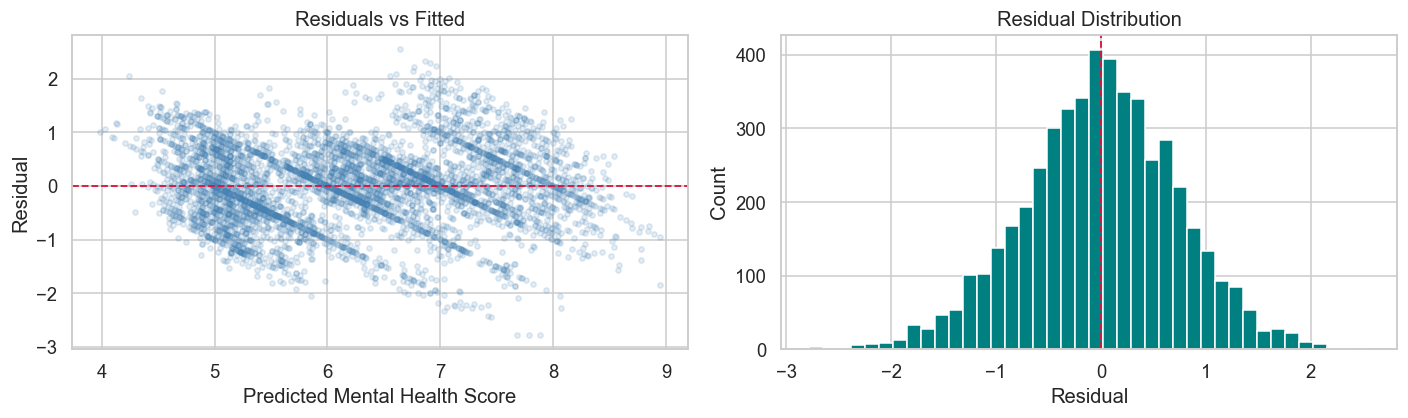

Residual mean = -0.0016, SD = 0.7356


In [28]:
y_reg = df[MHS_COL].values

lin = LinearRegression()
r2 = cross_val_score(lin, X_qol, y_reg, cv=5, scoring='r2')
rmse = -cross_val_score(lin, X_qol, y_reg, cv=5, scoring='neg_root_mean_squared_error')

print(f'Linear regression — {MHS_COL} ~ 3 quality-of-life features')
print(f'  CV R²   : {r2.mean():.4f} ± {r2.std():.4f}')
print(f'  CV RMSE : {rmse.mean():.4f} ± {rmse.std():.4f}   (outcome SD = {df[MHS_COL].std():.4f})')

# Standardized coefficients so the three features are on a comparable scale
lin_std = make_pipeline(StandardScaler(), LinearRegression())
lin_std.fit(X_qol, y_reg)
reg_coefs = pd.DataFrame({
    'Feature': QOL_COLS,
    'Coef (standardized)': lin_std.named_steps['linearregression'].coef_.round(4),
})
print('\nChange in mental-health score per one standard deviation increase:')
print(reg_coefs.to_string(index=False))

# Residual diagnostics on cross-validated predictions
pred = cross_val_predict(lin, X_qol, y_reg, cv=5)
resid = y_reg - pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(pred, resid, alpha=0.15, s=12, color='steelblue')
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=1.2)
axes[0].set_xlabel('Predicted Mental Health Score')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Fitted')

axes[1].hist(resid, bins=40, color='teal', edgecolor='white')
axes[1].axvline(0, color='crimson', linestyle='--', linewidth=1.2)
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution')

plt.tight_layout()
plt.show()

print(f'Residual mean = {resid.mean():+.4f}, SD = {resid.std():.4f}')

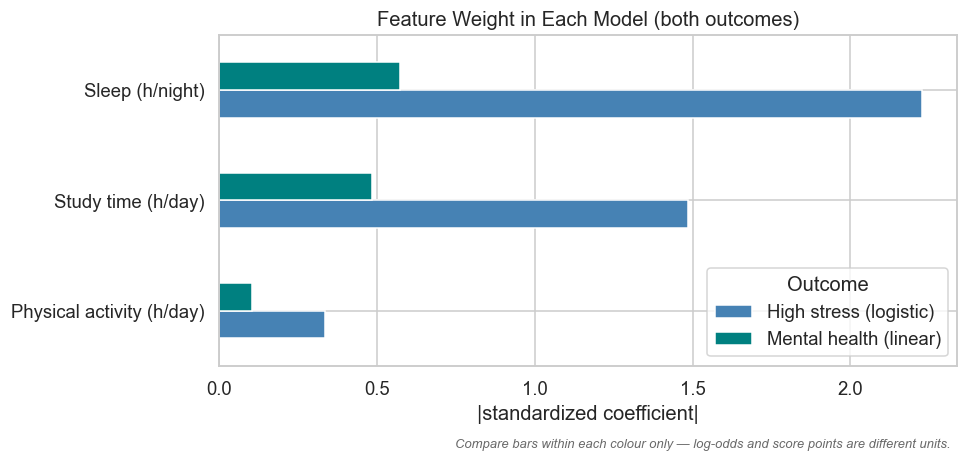

                           High stress (logistic)  Mental health (linear)
Feature                                                                  
Physical activity (h/day)                  0.3364                  0.1035
Study time (h/day)                         1.4869                  0.4859
Sleep (h/night)                            2.2281                  0.5724

Units differ between the two models (log-odds vs mental-health score points),
so read the ranking within each column, not the ratio across columns.


In [29]:
# Side-by-side view of which feature carries the weight in each model
comparison = pd.DataFrame({
    'Feature': [QOL_LABELS[c] for c in QOL_COLS],
    'High stress (logistic)': np.abs(logit.coef_[0]),
    'Mental health (linear)': np.abs(lin_std.named_steps['linearregression'].coef_),
}).set_index('Feature')

fig, ax = plt.subplots(figsize=(9, 4.5))
comparison.plot(kind='barh', ax=ax, color=['steelblue', 'teal'], edgecolor='white')
ax.set_xlabel('|standardized coefficient|')
ax.set_ylabel('')
ax.set_title('Feature Weight in Each Model (both outcomes)')
ax.legend(title='Outcome')
# The two models report coefficients in different units (log-odds vs score points), so
# only the ordering WITHIN each colour is meaningful — not the bar lengths between colours.
ax.text(0.99, -0.22, 'Compare bars within each colour only — log-odds and score points are different units.',
        transform=ax.transAxes, ha='right', va='top', fontsize=8.5, style='italic', color='dimgray')
plt.tight_layout()
plt.show()

print(comparison.round(4).to_string())
print('\nUnits differ between the two models (log-odds vs mental-health score points),')
print('so read the ranking within each column, not the ratio across columns.')

### What the results tell us

Both models are far better than their baselines. The classifier reaches roughly 88% accuracy and 0.96
ROC-AUC against a 61.2% majority-class baseline, and the regression reaches CV R² ≈ 0.66 — so the three
quality-of-life features jointly account for about two-thirds of the variation in mental-health score. The
residuals are centred on zero with no visible funnel or curvature, so the linear form is adequate.

The coefficients add the piece the correlations could not. In **both** models, on **both** outcomes, the
ordering is the same: **sleep > study > physical activity**, and physical activity's standardized weight is
under a fifth of sleep's in both. Once sleep and study time are in the model, physical activity contributes
very little — its marginal correlation of −0.56 was largely shared information, not independent signal.

(The two models' coefficients are in different units — log-odds for the classifier, score points for the
regression — so what transfers between them is the *ranking*, not the size of the numbers.)

One caveat on reading those weights. The three features are not independent of each other, so each
coefficient is a contribution *given the other two*, not a standalone effect — which is why the ranking
transfers between the models but the individual magnitudes should not be over-interpreted.

## 8. Direct Answer to Research Question 7

> **Is there a correlation between certain quality-of-life features and stress level?**

**Yes — all three quality-of-life features are strongly correlated with stress level, in exactly the
direction the research proposal predicted, and sleep hours is the strongest of the three.**

| Feature | ρ with stress | ε² (Kruskal–Wallis) | Cramér's V | r with mental-health score | Verdict |
|---|---|---|---|---|---|
| `Sleep_Hours_Per_Night` | −0.822 (very strong) | 0.678 | 0.515 | +0.766 | Strongest correlate on every test |
| `Study_Hours` | −0.800 (very strong) | 0.640 | 0.509 | +0.752 | Very strong, just behind sleep |
| `Physical_Activity_Hours` | −0.560 (strong) | 0.314 | 0.331 | +0.522 | Real, but clearly the weakest |

**Reading the table.** Every test agrees on both the direction and the ranking. H0 is rejected for all three
features by rank correlation, by Kruskal–Wallis, and by chi-square on
binned features; the continuous secondary outcome reproduces the identical ordering with the sign flipped;
and both models rank the features the same way, with basic machine learning reaching ≈ 88% accuracy
(vs a 61.2% baseline) on high stress and CV R² ≈ 0.66 on mental-health score. The proposal's expectation —
that more activity, study and sleep go with lower stress — is confirmed.

**Practical reading.** As *indicators*, all three work: knowing a student's sleep, study and activity hours
predicts their stress level well, and jointly they account for about two-thirds of the variation in
mental-health score. As *distinct factors*, they overlap heavily — section 7's coefficients put physical
activity at under a fifth of sleep's weight in both models, so most of its marginal correlation of −0.56 is
information that sleep and study time already carry. Sleep is the feature that stands on its own.

**Scope of this answer.** Every result above is a **marginal** association: each feature is examined against
stress without holding anything else in the dataset constant. That is what the research question asks for,
and it is what this notebook establishes. It is not a causal claim, and it does not rule out that some of
the association is carried by a variable outside these three — `Avg_Daily_Usage_Hours`, for instance,
correlates −0.89 with study hours and −0.83 with sleep, so the three features and daily usage are partly
measuring the same finite time budget from different ends.